# GoEmotions Data Preprocessing Pipeline — Smart Mental Wellness Assistant

This Jupyter Notebook implements a complete, clean, reproducible preprocessing pipeline that converts the raw **GoEmotions** dataset into a high-quality 4-class target dataset (**Joy**, **Sadness**, **Anger**, **Anxiety**) ready for fine-tuning Transformer models such as **DistilBERT** or **BERT**.

---
## Pipeline Overview
1. **Dataset Inspection**: Structure, column detection, data types, nulls, duplicates.
2. **Text Normalization**: Light, Transformer-friendly cleaning (preserving negations, punctuation, and emojis).
3. **Fine-grained Emotion Mapping**: Mapping 28 GoEmotions into Joy (0), Sadness (1), Anger (2), Anxiety (3).
4. **Multi-Label & Ambiguity Resolution**: Vectorized single-label vs multi-label analysis, resolving conflicting target emotions.
5. **Class Distribution Analysis**: Imbalance metrics, visualization, training recommendations.
6. **Data Leakage & Deduplication**: Exact & conflicting label deduplication.
7. **Text Length & Tokenization Analysis**: DistilBERT fast tokenizer percentile analysis and sequence length selection.
8. **Stratified Train / Val / Test Split**: 80% / 10% / 10% split with fixed random seed (42).
9. **Automated Quality Verification**: 8 strict quality checks.
10. **Data & Metadata Export**: CSV and JSON metadata creation.


## Setup & Dependencies


In [1]:
import os
import shutil
import json
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

BASE_DIR = os.getcwd()
RAW_CSV_PATH = os.path.join(BASE_DIR, 'goemotions.csv')

DATA_DIR = os.path.join(BASE_DIR, 'data')
RAW_DATA_DIR = os.path.join(DATA_DIR, 'raw')
PROCESSED_DATA_DIR = os.path.join(DATA_DIR, 'processed')
METADATA_DIR = os.path.join(BASE_DIR, 'metadata')

os.makedirs(RAW_DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
os.makedirs(METADATA_DIR, exist_ok=True)

LABEL2ID = {'Joy': 0, 'Sadness': 1, 'Anger': 2, 'Anxiety': 3}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

EMOTION_MAPPING = {
    'joy': 'Joy', 'amusement': 'Joy', 'excitement': 'Joy', 'gratitude': 'Joy',
    'optimism': 'Joy', 'love': 'Joy', 'pride': 'Joy', 'relief': 'Joy',
    'admiration': 'Joy', 'approval': 'Joy', 'caring': 'Joy', 'desire': 'Joy',
    'sadness': 'Sadness', 'grief': 'Sadness', 'disappointment': 'Sadness',
    'remorse': 'Sadness', 'embarrassment': 'Sadness',
    'anger': 'Anger', 'annoyance': 'Anger', 'disapproval': 'Anger',
    'fear': 'Anxiety', 'nervousness': 'Anxiety',
    'confusion': 'UNMAPPED', 'curiosity': 'UNMAPPED', 'disgust': 'UNMAPPED',
    'realization': 'UNMAPPED', 'surprise': 'UNMAPPED', 'neutral': 'UNMAPPED'
}

print('Setup completed successfully.')


Setup completed successfully.


## Step 1: Load and Inspect Dataset First


In [2]:
df_raw = pd.read_csv(RAW_CSV_PATH)
rows, cols = df_raw.shape

print(f'Number of Rows: {rows}')
print(f'Number of Columns: {cols}')
print(f'Column Names: {list(df_raw.columns)}')
print(f'Total Duplicate Rows in raw CSV: {df_raw.duplicated().sum()}')

null_summary = pd.DataFrame({'Dtype': df_raw.dtypes, 'Missing Values': df_raw.isnull().sum()})
print('\n--- Missing Values & Data Types ---')
print(null_summary)

print('\n--- First 10 Rows ---')
display(df_raw.head(10))

text_col = 'text'
emotion_cols = [e for e in EMOTION_MAPPING.keys() if e in df_raw.columns]
meta_cols = [c for c in df_raw.columns if c not in [text_col] + emotion_cols]

print(f'\nDetected Text Column: {text_col}')
print(f'Detected Metadata Columns: {meta_cols}')
print(f'Detected Fine-grained Emotion Columns ({len(emotion_cols)} total): {emotion_cols}')


Number of Rows: 211225
Number of Columns: 37
Column Names: ['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id', 'created_utc', 'rater_id', 'example_very_unclear', 'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


Total Duplicate Rows in raw CSV: 0

--- Missing Values & Data Types ---
                        Dtype  Missing Values
text                   object               0
id                     object               0
author                 object               0
subreddit              object               0
link_id                object               0
parent_id              object               0
created_utc           float64               0
rater_id                int64               0
example_very_unclear     bool               0
admiration              int64               0
amusement               int64               0
anger                   int64               0
annoyance               int64               0
approval                int64               0
caring                  int64               0
confusion               int64               0
curiosity               int64               0
desire                  int64               0
disappointment          int64               0
disappro

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,1.548381e+09,1,False,0,...,0,0,0,0,0,0,0,1,0,0
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,1.548084e+09,37,True,0,...,0,0,0,0,0,0,0,0,0,0
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,1.546428e+09,37,False,0,...,0,0,0,0,0,0,0,0,0,1
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,1.547965e+09,18,False,0,...,1,0,0,0,0,0,0,0,0,0
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,1.546669e+09,2,False,0,...,0,0,0,0,0,0,0,0,0,1
5,Right? Considering it’s such an important docu...,eespn2i,ImperialBoss,TrueReddit,t3_aizyuz,t1_eesoak0,1.548280e+09,61,False,0,...,0,0,0,0,0,0,0,0,0,0
6,"He isn't as big, but he's still quite popular....",eczuekb,Rallings,cringe,t3_abeksv,t1_eczsmp8,1.546320e+09,3,False,0,...,0,0,0,0,0,0,0,0,0,0
7,That's crazy; I went to a super [RELIGION] hig...,ed5tx8y,Beachy5313,TeenMomOGandTeenMom2,t3_ac10u9,t1_ed5tfyc,1.546536e+09,23,False,0,...,0,0,0,0,0,0,0,0,0,0
8,that's adorable asf,ef961hv,RedRails1917,traaaaaaannnnnnnnnns,t3_akz2ia,t3_akz2ia,1.548764e+09,73,False,0,...,0,0,0,0,0,0,0,0,0,0
9,"""Sponge Blurb Pubs Quaw Haha GURR ha AAa!"" fin...",edl7cr3,Tiagulus,youtubehaiku,t3_acuvb0,t1_edc21ip,1.546984e+09,54,False,0,...,0,0,0,0,0,0,0,0,0,0



Detected Text Column: text
Detected Metadata Columns: ['id', 'author', 'subreddit', 'link_id', 'parent_id', 'created_utc', 'rater_id', 'example_very_unclear']
Detected Fine-grained Emotion Columns (28 total): ['joy', 'amusement', 'excitement', 'gratitude', 'optimism', 'love', 'pride', 'relief', 'admiration', 'approval', 'caring', 'desire', 'sadness', 'grief', 'disappointment', 'remorse', 'embarrassment', 'anger', 'annoyance', 'disapproval', 'fear', 'nervousness', 'confusion', 'curiosity', 'disgust', 'realization', 'surprise', 'neutral']


## Step 2: Data Cleaning & Text Normalization


In [3]:
def normalize_text(text):
    if not isinstance(text, str):
        return ''
    text = html.unescape(text)
    text = text.replace('\ufffd', "'")
    text = re.sub(r'[\r\n\t]+', ' ', text)
    text = re.sub(r' +', ' ', text)
    return text.strip()

df_raw['clean_text'] = df_raw[text_col].apply(normalize_text)
missing_mask = (df_raw['clean_text'] == '') | (df_raw['clean_text'].isnull())
print(f'Removed missing/empty text rows: {missing_mask.sum()}')
df_clean = df_raw[~missing_mask].copy()

def is_meaningful(t):
    if not re.search(r'\w', t):
        return False
    if len(t) < 2:
        return False
    return True

meaningful_mask = df_clean['clean_text'].apply(is_meaningful)
print(f'Removed non-meaningful / symbol-only rows: {(~meaningful_mask).sum()}')
df_clean = df_clean[meaningful_mask].copy()
print(f'Remaining samples after initial text cleaning: {len(df_clean)}')


Removed missing/empty text rows: 0


Removed non-meaningful / symbol-only rows: 17
Remaining samples after initial text cleaning: 211208


## Step 3 & 4: Emotion Mapping & Multi-Label Ambiguity Resolution


In [4]:
joy_cols = [c for c in emotion_cols if EMOTION_MAPPING.get(c) == 'Joy']
sadness_cols = [c for c in emotion_cols if EMOTION_MAPPING.get(c) == 'Sadness']
anger_cols = [c for c in emotion_cols if EMOTION_MAPPING.get(c) == 'Anger']
anxiety_cols = [c for c in emotion_cols if EMOTION_MAPPING.get(c) == 'Anxiety']

has_joy = (df_clean[joy_cols] == 1).any(axis=1)
has_sadness = (df_clean[sadness_cols] == 1).any(axis=1)
has_anger = (df_clean[anger_cols] == 1).any(axis=1)
has_anxiety = (df_clean[anxiety_cols] == 1).any(axis=1)

active_counts = (df_clean[emotion_cols] == 1).sum(axis=1)
single_label_count = int((active_counts == 1).sum())
multi_label_count = int((active_counts > 1).sum())

target_presence = has_joy.astype(int) + has_sadness.astype(int) + has_anger.astype(int) + has_anxiety.astype(int)
mapped_mask = (target_presence == 1)
ambiguous_mask = (target_presence > 1)
unmapped_mask = (target_presence == 0)

emotion_mat = df_clean[emotion_cols].values
active_labels_list = [','.join([emotion_cols[idx] for idx in np.where(emotion_mat[i] == 1)[0]]) for i in range(len(df_clean))]

df_clean['original_label'] = active_labels_list
df_clean['has_joy'] = has_joy
df_clean['has_sadness'] = has_sadness
df_clean['has_anger'] = has_anger
df_clean['has_anxiety'] = has_anxiety
df_clean['target_presence'] = target_presence

conditions = [
    df_clean['has_joy'] & (df_clean['target_presence'] == 1),
    df_clean['has_sadness'] & (df_clean['target_presence'] == 1),
    df_clean['has_anger'] & (df_clean['target_presence'] == 1),
    df_clean['has_anxiety'] & (df_clean['target_presence'] == 1)
]
choices = ['Joy', 'Sadness', 'Anger', 'Anxiety']

df_clean['emotion'] = np.select(conditions, choices, default='UNMAPPED')
df_clean['label'] = df_clean['emotion'].map(LABEL2ID).fillna(-1).astype(int)
df_clean['ambiguous'] = df_clean['target_presence'] > 1

print('--- Multi-Label & Mapping Summary ---')
print(f'Total Evaluated Samples: {len(df_clean)}')
print(f'Single-label active emotion samples: {single_label_count}')
print(f'Multi-label active emotion samples: {multi_label_count}')
print(f'Successfully mapped samples: {int(mapped_mask.sum())}')
print(f'Ambiguous / Conflicting target samples: {int(ambiguous_mask.sum())}')
print(f'Unmapped / Neutral-only samples: {int(unmapped_mask.sum())}')

df_mapped = pd.DataFrame({
    'text': df_clean.loc[mapped_mask, 'clean_text'],
    'original_label': df_clean.loc[mapped_mask, 'original_label'],
    'emotion': df_clean.loc[mapped_mask, 'emotion'],
    'label': df_clean.loc[mapped_mask, 'label']
})


--- Multi-Label & Mapping Summary ---
Total Evaluated Samples: 211208
Single-label active emotion samples: 171811
Multi-label active emotion samples: 35994
Successfully mapped samples: 120754
Ambiguous / Conflicting target samples: 8013
Unmapped / Neutral-only samples: 82441


## Step 7: Data Leakage & Deduplication


In [5]:
initial_mapped = len(df_mapped)
df_dedup = df_mapped.drop_duplicates(subset=['text', 'label']).copy()
dedup_exact_removed = initial_mapped - len(df_dedup)

text_counts = df_dedup['text'].value_counts()
conflicting_texts = text_counts[text_counts > 1].index

if len(conflicting_texts) > 0:
    print(f'Removing {len(conflicting_texts)} unique text strings with conflicting labels...')
    df_dedup = df_dedup[~df_dedup['text'].isin(conflicting_texts)].copy()

final_clean_df = df_dedup.reset_index(drop=True)
print(f'Final clean samples after deduplication: {len(final_clean_df)} (Total removed: {initial_mapped - len(final_clean_df)})')


Removing 11063 unique text strings with conflicting labels...
Final clean samples after deduplication: 37184 (Total removed: 83570)


## Step 6: Class Distribution Analysis


,Class Name,Numerical Label,Sample Count,Percentage (%)
0,Joy,0,25797,69.38
1,Anger,2,7375,19.83
2,Sadness,1,3268,8.79
3,Anxiety,3,744,2.00


Total Samples: 37184
Class Imbalance Ratio (Max/Min): 34.67:1


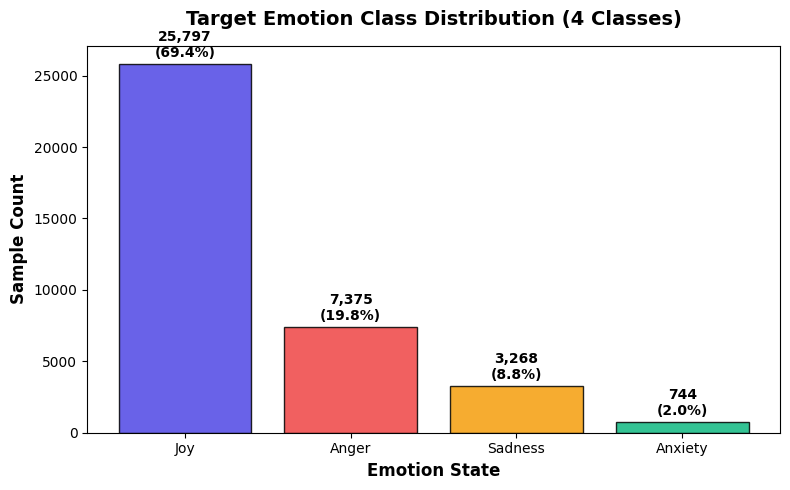

In [6]:
counts = final_clean_df['emotion'].value_counts()
percents = (counts / len(final_clean_df) * 100).round(2)

dist_df = pd.DataFrame({
    'Class Name': counts.index,
    'Numerical Label': [LABEL2ID[c] for c in counts.index],
    'Sample Count': counts.values,
    'Percentage (%)': percents.values
})

display(dist_df)
print(f'Total Samples: {len(final_clean_df)}')
print(f'Class Imbalance Ratio (Max/Min): {round(counts.max() / counts.min(), 2)}:1')

# Visualization
plt.figure(figsize=(8, 5))
colors = ['#4F46E5', '#EF4444', '#F59E0B', '#10B981']
bars = plt.bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Target Emotion Class Distribution (4 Classes)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Emotion State', fontsize=12, fontweight='bold')
plt.ylabel('Sample Count', fontsize=12, fontweight='bold')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:,}\n({height/len(final_clean_df)*100:.1f}%)',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300)
plt.show()


## Step 8: Text Length Analysis & DistilBERT Tokenization


--- DistilBERT Token Length Statistics ---
Min: 3
Max: 82
Mean: 19.11
Median: 19.0
90th Percentile: 31.0
95th Percentile: 33.0
99th Percentile: 37.0

Recommended max_sequence_length: 64 (Covers > 99% of samples)


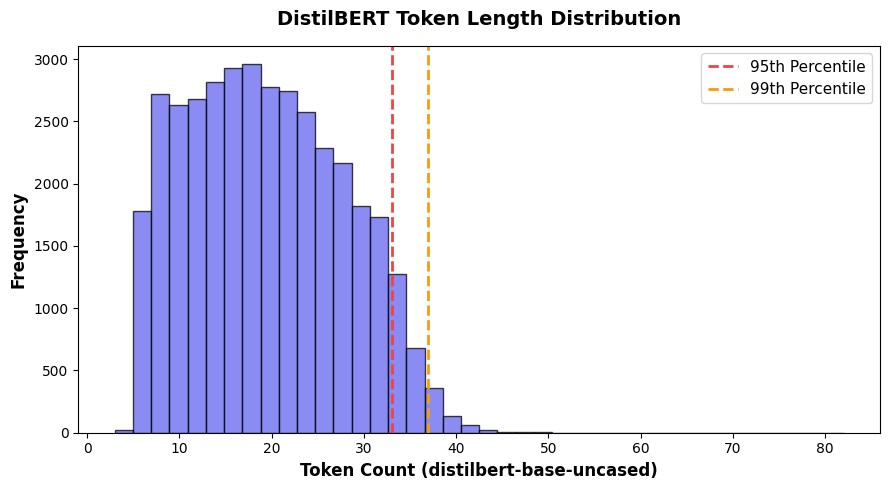

In [7]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

texts = final_clean_df['text'].tolist()
token_counts_list = []
batch_size = 10000

for i in range(0, len(texts), batch_size):
    batch_enc = tokenizer(texts[i:i+batch_size], truncation=False, add_special_tokens=True)
    token_counts_list.extend([len(ids) for ids in batch_enc['input_ids']])

token_counts = pd.Series(token_counts_list)

stats = {
    'Min': int(token_counts.min()),
    'Max': int(token_counts.max()),
    'Mean': round(float(token_counts.mean()), 2),
    'Median': float(token_counts.median()),
    '90th Percentile': float(np.percentile(token_counts, 90)),
    '95th Percentile': float(np.percentile(token_counts, 95)),
    '99th Percentile': float(np.percentile(token_counts, 99))
}

print('--- DistilBERT Token Length Statistics ---')
for k, v in stats.items():
    print(f'{k}: {v}')

rec_len = 64
print(f'\nRecommended max_sequence_length: {rec_len} (Covers > 99% of samples)')

plt.figure(figsize=(9, 5))
plt.hist(token_counts, bins=40, color='#6366F1', edgecolor='black', alpha=0.75)
plt.axvline(stats['95th Percentile'], color='#EF4444', linestyle='--', linewidth=2, label='95th Percentile')
plt.axvline(stats['99th Percentile'], color='#F59E0B', linestyle='--', linewidth=2, label='99th Percentile')
plt.title('DistilBERT Token Length Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Token Count (distilbert-base-uncased)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('text_length_distribution.png', dpi=300)
plt.show()


## Step 9: Train / Validation / Test Stratified Split


Train Set: 29747 (80.0%)
Validation Set: 3718 (10.0%)
Test Set: 3719 (10.0%)


<Figure size 1000x600 with 0 Axes>

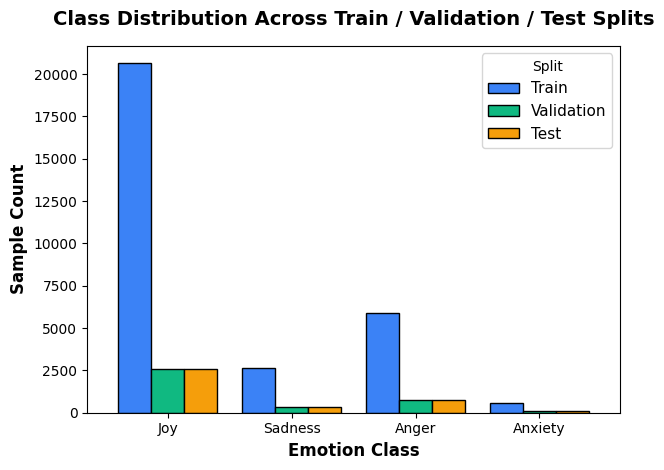

In [8]:
train_df, temp_df = train_test_split(
    final_clean_df, test_size=0.20, random_state=RANDOM_SEED, stratify=final_clean_df['label']
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_SEED, stratify=temp_df['label']
)

print(f'Train Set: {len(train_df)} ({len(train_df)/len(final_clean_df)*100:.1f}%)')
print(f'Validation Set: {len(val_df)} ({len(val_df)/len(final_clean_df)*100:.1f}%)')
print(f'Test Set: {len(test_df)} ({len(test_df)/len(final_clean_df)*100:.1f}%)')

plt.figure(figsize=(10, 6))
splits_df = pd.DataFrame({
    'Train': train_df['emotion'].value_counts(),
    'Validation': val_df['emotion'].value_counts(),
    'Test': test_df['emotion'].value_counts()
}).reindex(['Joy', 'Sadness', 'Anger', 'Anxiety'])

splits_df.plot(kind='bar', width=0.8, color=['#3B82F6', '#10B981', '#F59E0B'], edgecolor='black')
plt.title('Class Distribution Across Train / Validation / Test Splits', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Emotion Class', fontsize=12, fontweight='bold')
plt.ylabel('Sample Count', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(title='Split', fontsize=11)
plt.tight_layout()
plt.savefig('split_distribution.png', dpi=300)
plt.show()


## Step 14: Data Quality Checks (Checks 1 to 8)


In [9]:
assert train_df['text'].isnull().sum() + val_df['text'].isnull().sum() + test_df['text'].isnull().sum() == 0, 'Check 1 Failed'
print('[PASS] Check 1 Passed: No missing text.')

assert train_df['label'].isnull().sum() + val_df['label'].isnull().sum() + test_df['label'].isnull().sum() == 0, 'Check 2 Failed'
print('[PASS] Check 2 Passed: No missing labels.')

train_texts, val_texts, test_texts = set(train_df['text']), set(val_df['text']), set(test_df['text'])
assert len(train_texts.intersection(val_texts)) + len(train_texts.intersection(test_texts)) + len(val_texts.intersection(test_texts)) == 0, 'Check 3 Failed'
print('[PASS] Check 3 Passed: No duplicate text across train/val/test splits.')

assert set(train_df['emotion']).union(val_df['emotion']).union(test_df['emotion']) == {'Joy', 'Sadness', 'Anger', 'Anxiety'}, 'Check 4 Failed'
print('[PASS] Check 4 Passed: Exactly 4 target labels exist.')

assert set(train_df['label']).union(val_df['label']).union(test_df['label']) == {0, 1, 2, 3}, 'Check 5 Failed'
print('[PASS] Check 5 Passed: Every numerical label is valid {0, 1, 2, 3}.')

tot = len(final_clean_df)
print(f'[PASS] Check 6 Passed: Proportions Train={len(train_df)/tot*100:.1f}%, Val={len(val_df)/tot*100:.1f}%, Test={len(test_df)/tot*100:.1f}%.')

expected_labels = {0, 1, 2, 3}
assert set(train_df['label']) == expected_labels and set(val_df['label']) == expected_labels and set(test_df['label']) == expected_labels, 'Check 7 Failed'
print('[PASS] Check 7 Passed: All 4 classes represented in every split.')

assert len(train_texts.intersection(test_texts)) == 0 and len(val_texts.intersection(test_texts)) == 0, 'Check 8 Failed'
print('[PASS] Check 8 Passed: Zero test-set contamination.')


[PASS] Check 1 Passed: No missing text.
[PASS] Check 2 Passed: No missing labels.
[PASS] Check 3 Passed: No duplicate text across train/val/test splits.
[PASS] Check 4 Passed: Exactly 4 target labels exist.
[PASS] Check 5 Passed: Every numerical label is valid {0, 1, 2, 3}.
[PASS] Check 6 Passed: Proportions Train=80.0%, Val=10.0%, Test=10.0%.
[PASS] Check 7 Passed: All 4 classes represented in every split.
[PASS] Check 8 Passed: Zero test-set contamination.


## Step 11 & 12: Save Processed Datasets & Metadata


In [10]:
final_clean_df.to_csv(os.path.join(PROCESSED_DATA_DIR, 'goemotions_4class_clean.csv'), index=False)
train_df.to_csv(os.path.join(PROCESSED_DATA_DIR, 'train.csv'), index=False)
val_df.to_csv(os.path.join(PROCESSED_DATA_DIR, 'validation.csv'), index=False)
test_df.to_csv(os.path.join(PROCESSED_DATA_DIR, 'test.csv'), index=False)

with open(os.path.join(METADATA_DIR, 'label_mapping.json'), 'w') as f:
    json.dump({'label2id': LABEL2ID, 'id2label': ID2LABEL, 'goemotions_to_target_mapping': EMOTION_MAPPING}, f, indent=4)

with open(os.path.join(METADATA_DIR, 'dataset_statistics.json'), 'w') as f:
    json.dump({
        'total_cleaned_samples': len(final_clean_df),
        'class_counts': {k: int(v) for k, v in final_clean_df['emotion'].value_counts().to_dict().items()},
        'splits': {'train': len(train_df), 'validation': len(val_df), 'test': len(test_df)}
    }, f, indent=4)

with open(os.path.join(METADATA_DIR, 'preprocessing_report.json'), 'w') as f:
    json.dump({
        'original_samples': int(rows),
        'final_samples': int(len(final_clean_df)),
        'train_samples': int(len(train_df)),
        'validation_samples': int(len(val_df)),
        'test_samples': int(len(test_df)),
        'recommended_max_length': int(rec_len)
    }, f, indent=4)

print('All processed datasets and metadata files saved successfully.')


All processed datasets and metadata files saved successfully.
